# Ping Lab · pierwszy przegląd nagrań
**Cel spotkania:** ustalić, czy w nagraniach widać i słychać powtarzalny sygnał wady oraz co poprawić w pomiarach.

**Start:** otwórz folder projektu w VS Code → wybierz kernel `.venv` / **Ping Lab (Python)** → **Run All**.
Wszystkie notebooki czytają `project.json`. Po otrzymaniu danych zmień tam manifest, typ danych i katalog wyników.
Każdy `plate_id` oznacza fizyczną płytę; kilka uderzeń nie zwiększa liczby niezależnych przykładów.

Ten plik nadaje się do przeglądu z zapisanymi wynikami. Do ponownego uruchomienia potrzebny jest dołączony projekt.

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Otwórz cały folder projektu w VS Code."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
from pinglab.audio import Config, load_audio, detect_hits, cut_hits, listen
from pinglab.session import load_session
SESSION = load_session(ROOT)
CONFIG, FMAX = SESSION.config, SESSION.fmax
MANIFEST, ANNOTATIONS = SESSION.manifest, SESSION.annotations
print("Dane:", SESSION.source_kind, "· manifest:", MANIFEST.relative_to(ROOT) if MANIFEST.is_relative_to(ROOT) else MANIFEST.name)
print("Wspólne pasmo do", FMAX, "Hz · konfiguracja: project.json")
if SESSION.source_kind == "synthetic":
    display(Markdown("**SYMULACJA — wynik sprawdza narzędzia, nie wykrywanie pęknięć u klienta.**"))


Dane: synthetic · manifest: data/demo/manifest.csv
Wspólne pasmo do 20000.0 Hz · konfiguracja: project.json


**SYMULACJA — wynik sprawdza narzędzia, nie wykrywanie pęknięć u klienta.**

## 1. Co dostaliśmy?
Niepewne oceny oznacz `unknown`. Typ płyty, temperatura i sesja pomagają odróżnić wadę od warunków nagrania.

In [2]:
from pinglab.exploration import audio_gallery, spectrogram_gallery, feature_atlas, metadata_audit
from pinglab.dataset import analyze_manifest
OUT = SESSION.output / 'exploration'
records = SESSION.records
objects = records[records.label != 'background']
display(objects.groupby('label').agg(pliki=('path','size'), plyty=('plate_id','nunique')))
display(objects[['path','plate_id','label','session_id','plate_type','temperature']])
print('Źródło:', SESSION.source_kind, '· plików tła:', int(records.label.eq('background').sum()))

,pliki,plyty
label,,
nok,10,10
ok,20,20


,path,plate_id,label,session_id,plate_type,temperature
0,SYN_001_ok.wav,SYN_001,ok,S1,,
1,SYN_002_ok.wav,SYN_002,ok,S2,,
2,SYN_003_ok.wav,SYN_003,ok,S3,,
3,SYN_004_ok.wav,SYN_004,ok,S1,,
4,SYN_005_ok.wav,SYN_005,ok,S2,,
5,SYN_006_ok.wav,SYN_006,ok,S3,,
6,SYN_007_ok.wav,SYN_007,ok,S1,,
7,SYN_008_ok.wav,SYN_008,ok,S2,,
8,SYN_009_ok.wav,SYN_009,ok,S3,,
9,SYN_010_ok.wav,SYN_010,ok,S1,,


Źródło: synthetic · plików tła: 1


## 2. Jakość i podział na uderzenia
Sprawdź przesterowanie, za ciche nagrania i liczbę kandydatów. „Auto” wymaga odsłuchu — mowa lub stuknięcie stołu także mogą przekroczyć próg. Korektę sekund zapiszesz w notebooku 02.

In [3]:
events, quality = analyze_manifest(MANIFEST, OUT, CONFIG, FMAX,
    ANNOTATIONS if ANNOTATIONS.exists() else None)
display(quality[['path','native_sr','peak_dbfs','clipping_fraction','n_hits','reviewed','warnings']])
print('Uderzenia:', len(events), '· pliki bez uderzeń:', int(((quality.label!='background') & quality.n_hits.eq(0)).sum()))
if not events.empty:
    print('Skrócone okna:', int(events.truncated.sum()), '— sprawdź odstęp uderzeń i długość ogona.')

,path,native_sr,peak_dbfs,clipping_fraction,n_hits,reviewed,warnings
0,SYN_001_ok.wav,48000,-3.956122,0.0,3,True,
1,SYN_002_ok.wav,48000,-3.134742,0.0,3,True,
2,SYN_003_ok.wav,48000,-3.305335,0.0,3,True,
3,SYN_004_ok.wav,48000,-3.730169,0.0,3,True,
4,SYN_005_ok.wav,48000,-4.800968,0.0,3,True,
5,SYN_006_ok.wav,48000,-6.851207,0.0,3,True,
6,SYN_007_ok.wav,48000,-3.547069,0.0,3,True,
7,SYN_008_ok.wav,48000,-5.650114,0.0,3,True,
8,SYN_009_ok.wav,48000,-6.536152,0.0,3,True,
9,SYN_010_ok.wav,48000,-5.302261,0.0,3,True,


Uderzenia: 90 · pliki bez uderzeń: 0
Skrócone okna: 0 — sprawdź odstęp uderzeń i długość ogona.


## 3. Odsłuch każdego pliku
Rozwiń wybrane nagranie. Głośność oryginalna; różnica poziomu nie jest dowodem wady. Po odsłuchu zanotuj, jaką różnicę słyszy operator.

In [4]:
audio_gallery(SESSION)

## 4. Galeria: sygnał i spektrogram
Pomarańczowe kreski to początki kandydatów. Jasne poziome pasma wskazują rezonanse, ich długość — wybrzmiewanie. Skala jest względna dla każdego pliku; kolory nie porównują bezwzględnej głośności.

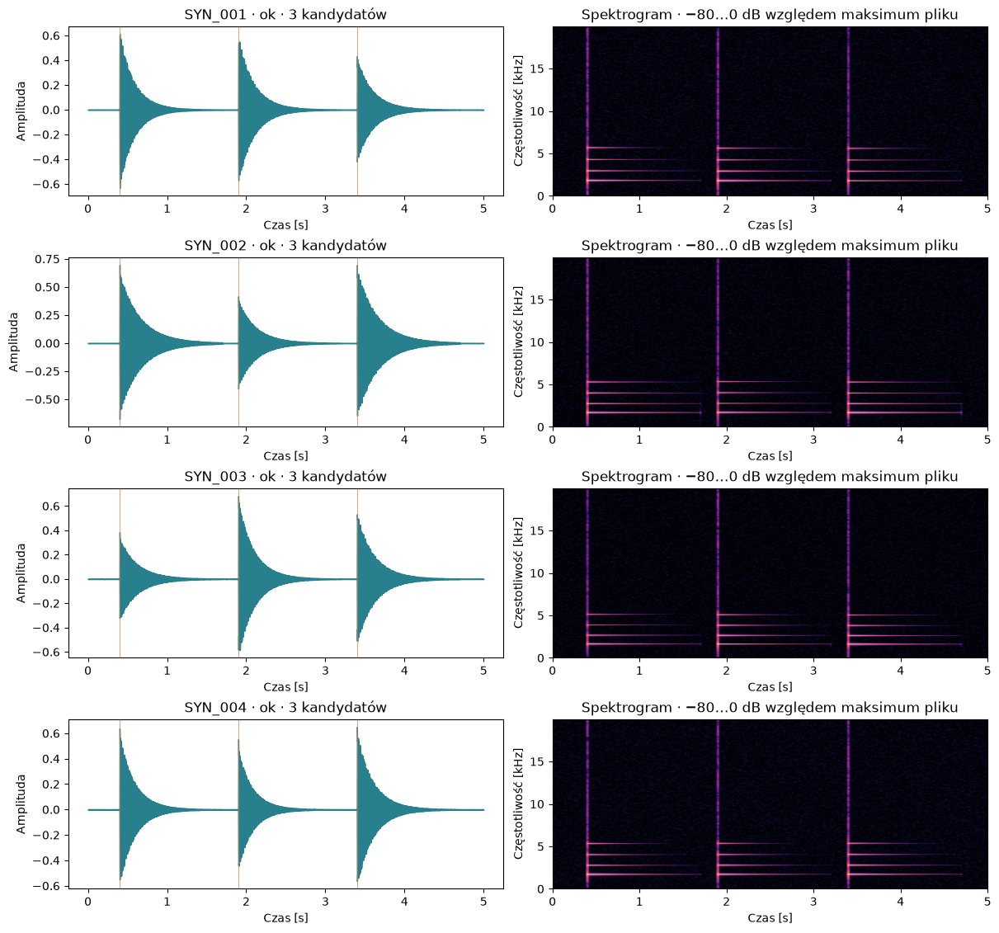

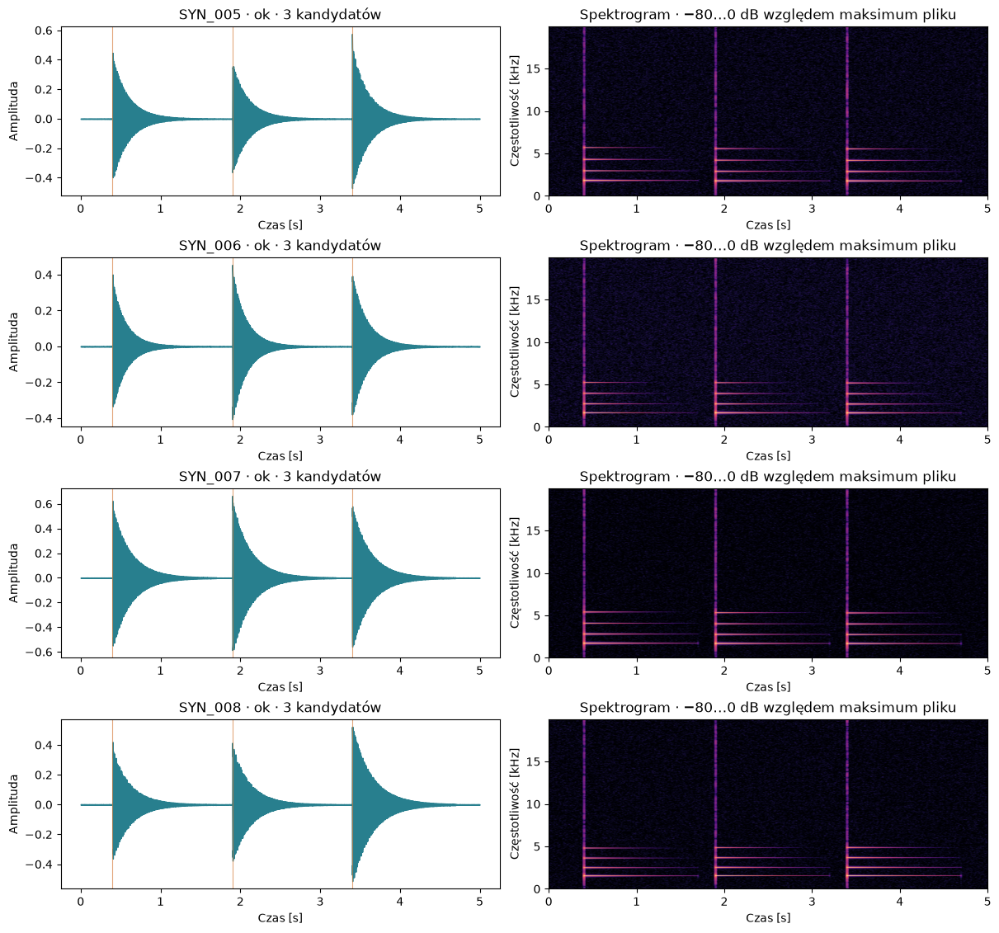

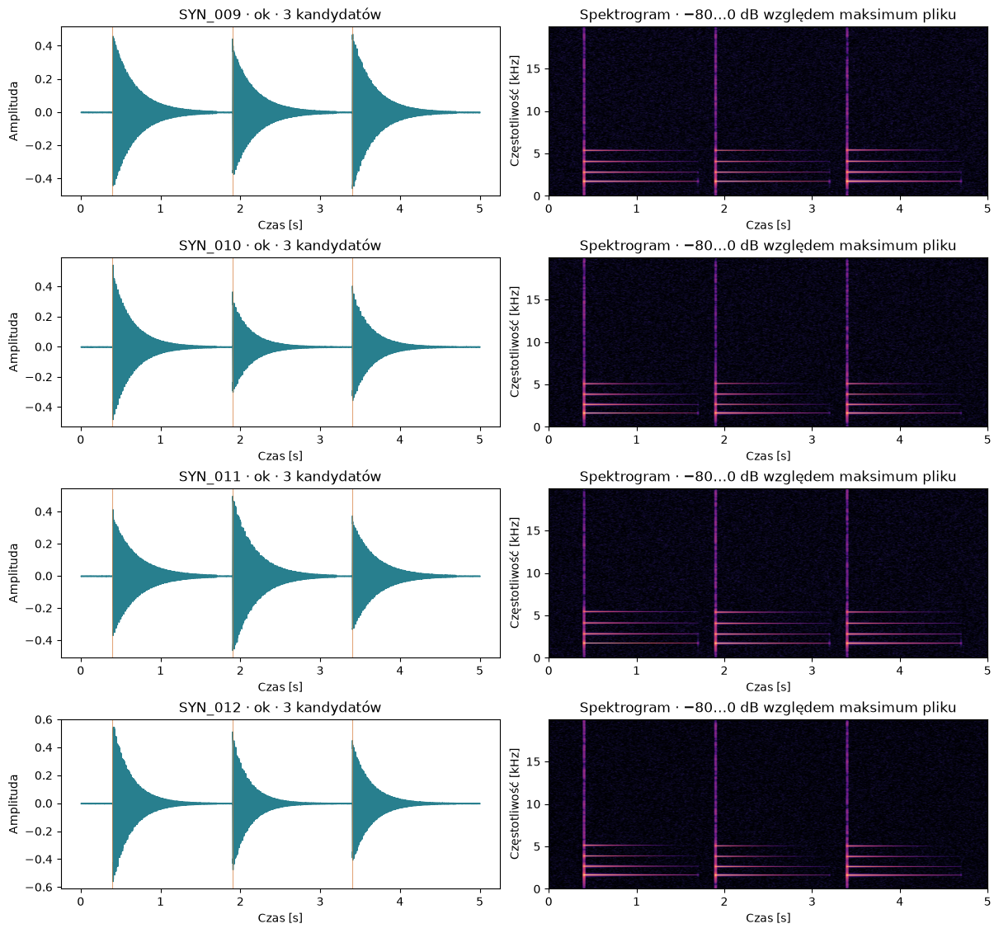

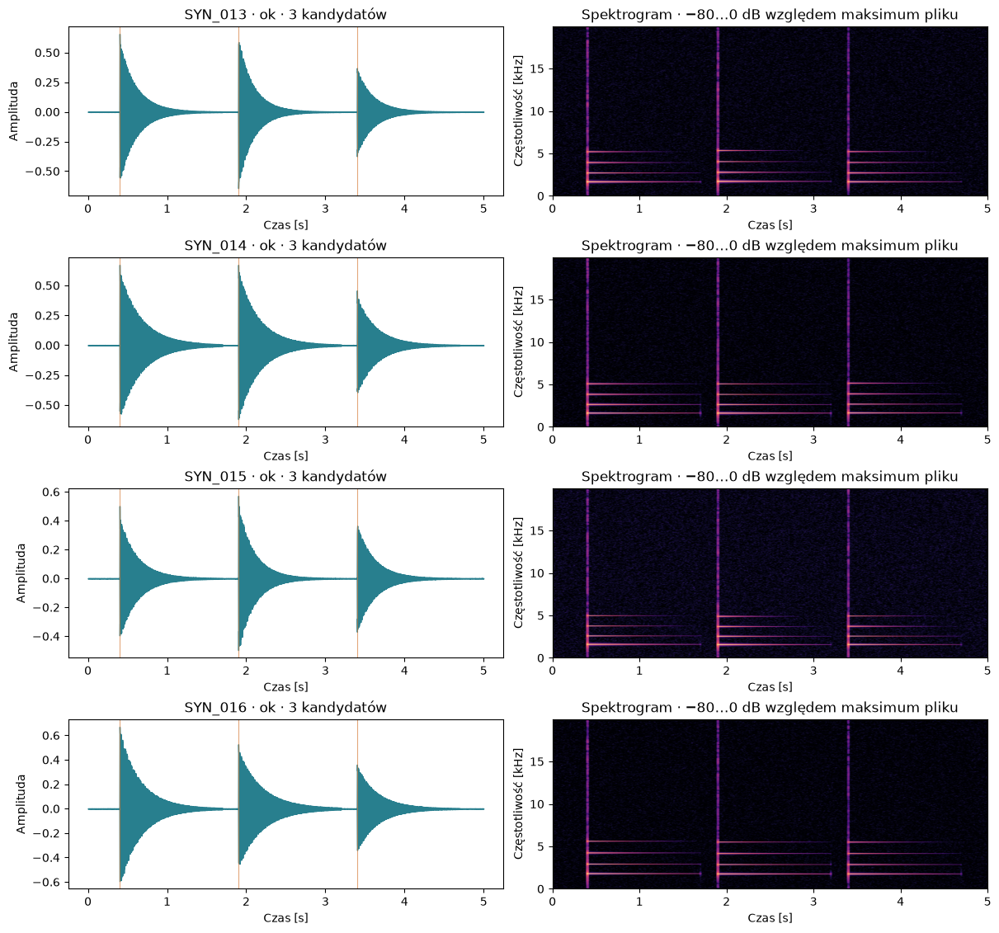

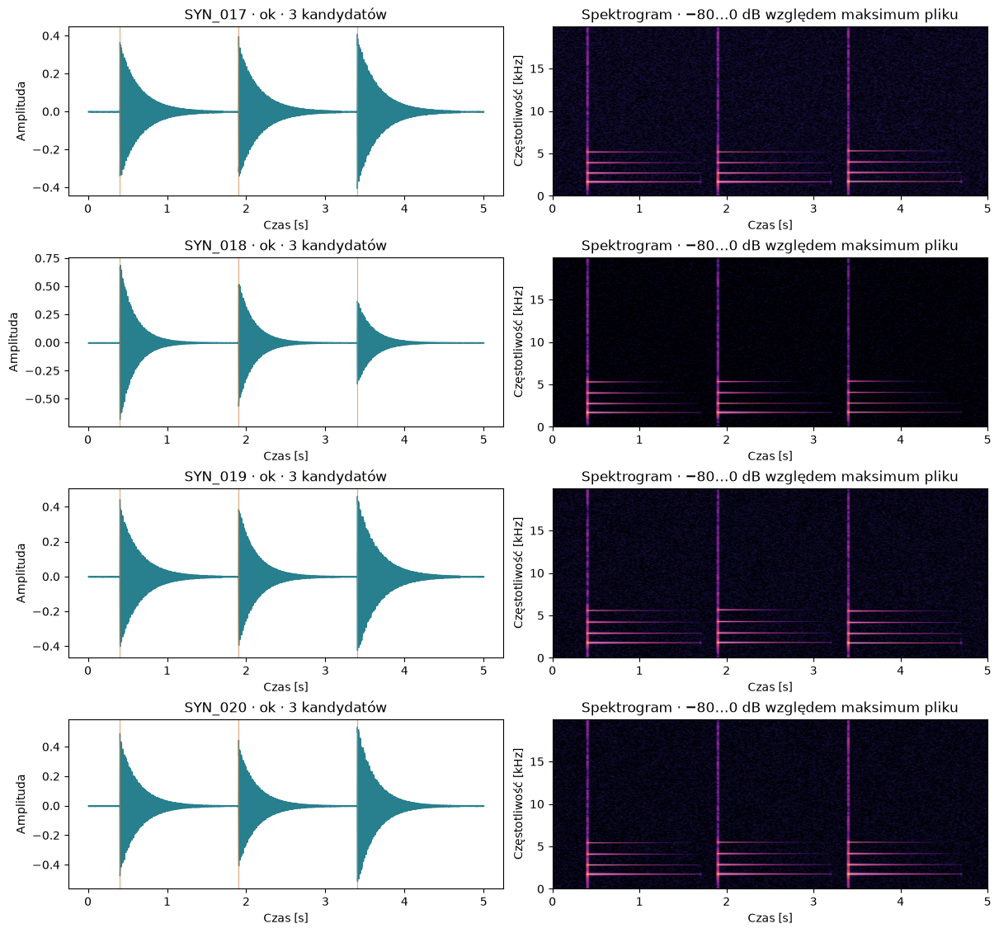

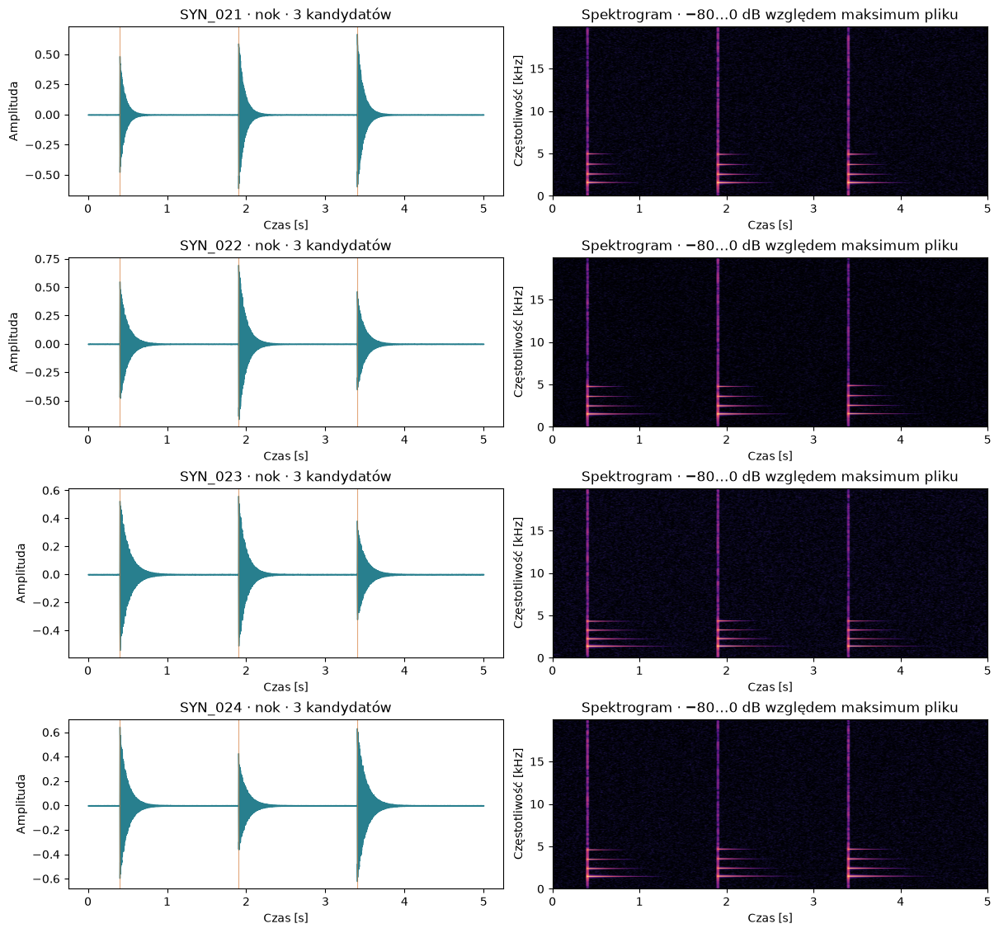

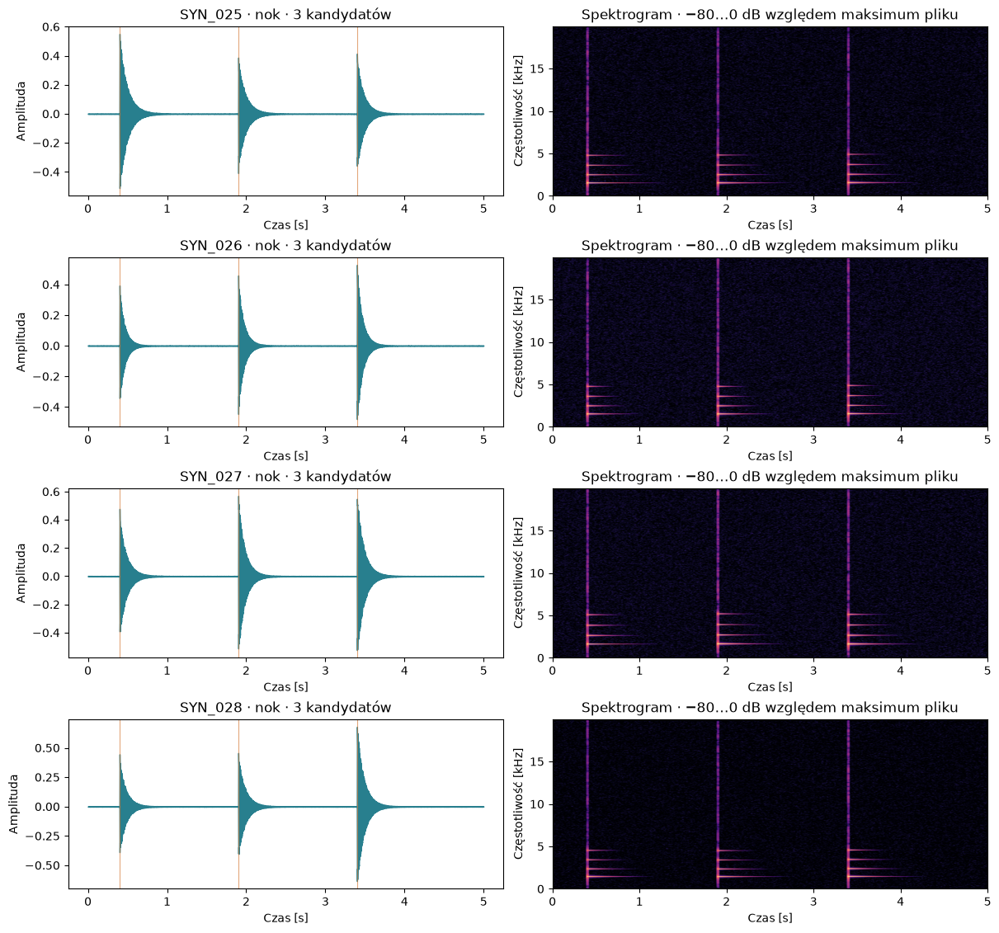

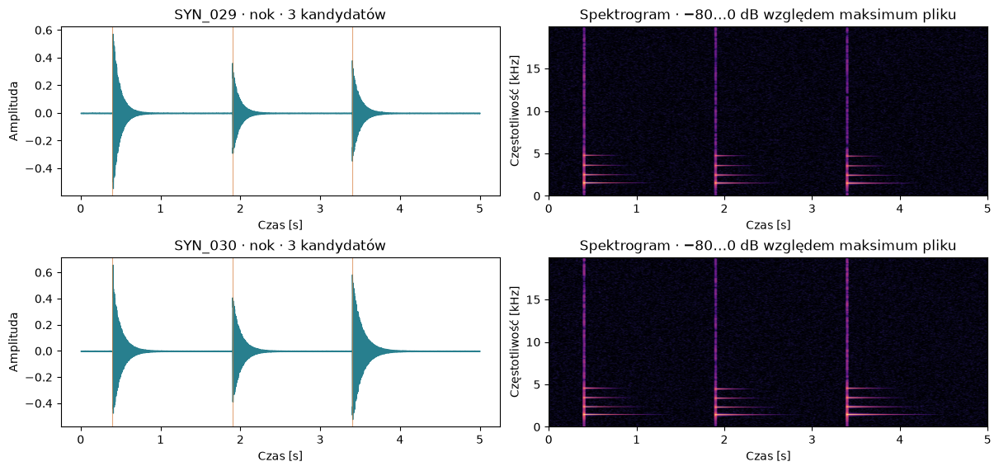

In [5]:
spectrogram_gallery(SESSION)

## 5. Czy cechy są powtarzalne?
Zobacz częstotliwość i zanik oraz rozrzut uderzeń na tej samej płycie. Duży rozrzut może oznaczać lokalną wadę, ale także zmienne miejsce lub siłę uderzenia. Zanik o 10 dB jest opisem okna, nie pomiarem stałej materiałowej.

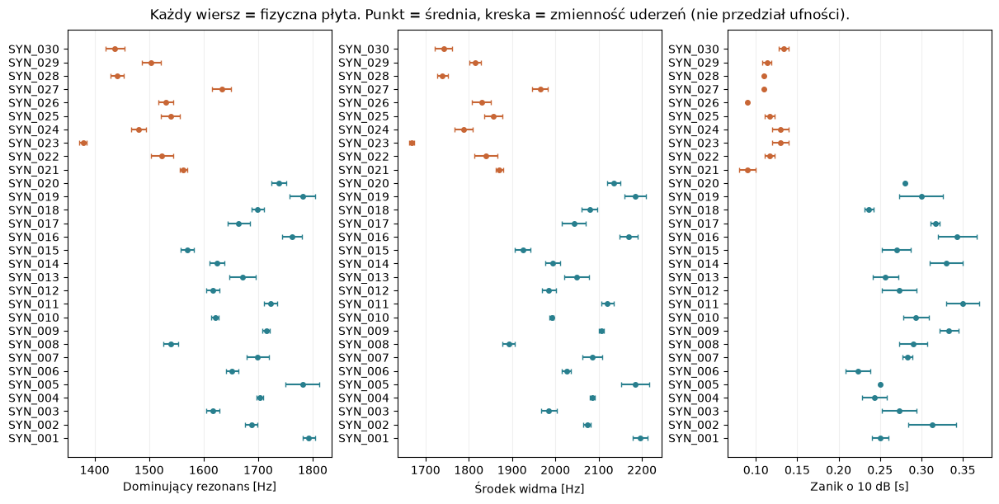

In [6]:
feature_atlas(events)

## 6. Czy porównujemy podobne warunki?
Jeżeli wszystkie NOK pochodzą z jednej sesji lub mają inny typ, model może rozpoznawać warunki zamiast pęknięcia.

In [7]:
metadata = metadata_audit(SESSION)

**session_id** — liczba płyt; puste oznacza brak informacji

label,nok,ok
session_id,,
S1,3,7
S2,3,7
S3,4,6


**plate_type** — liczba płyt; puste oznacza brak informacji

label,nok,ok
plate_type,,
brak,10,20


**temperature** — liczba płyt; puste oznacza brak informacji

label,nok,ok
temperature,,
brak,10,20


## 7. Pierwsze proste modele
Porównujemy **odległość od dobrych wzorców**, **regresję logistyczną na rezonansach i ich zmienności** oraz **MFCC + średnią z 3 najwyższych ocen uderzeń**.
Każda oceniana płyta jest poza treningiem. Przy małej próbie modelowanie zostanie pominięte.

Próg jest ustalany wewnątrz treningu, jeśli wystarcza danych; inaczej używamy jawnego progu stałego.
**Recall NOK** = część wykrytych wad. **False reject** = część dobrych płyt odrzuconych. Żaden wynik na demo nie potwierdza skuteczności u klienta.

In [8]:
from pinglab.benchmark import benchmark
leaderboard = predictions = folds = taps = None
if events.empty:
    print('Modelowanie pominięte: brak uderzeń.')
else:
    try:
        leaderboard, predictions, folds, taps = benchmark(events)
        display(leaderboard[['method','n_plates','recall_nok','false_reject','missed_nok','roc_auc','average_precision','recall_cp95']].round(3))
        display(predictions.groupby(['method','threshold_policy']).size().rename('płyty'))
        leaderboard.to_json(OUT/'leaderboard.json',orient='records',indent=2)
        predictions.to_csv(OUT/'predictions.csv',index=False)
        (OUT/'folds.json').write_text(json.dumps(folds,indent=2))
    except ValueError as error:
        print('Modelowanie pominięte:', error)

,method,n_plates,recall_nok,false_reject,missed_nok,roc_auc,average_precision,recall_cp95
0,A_distance,30,0.9,0.0,1,1.0,1.0,"[0.5549838829718047, 0.9974714214555382]"
1,A_logistic,30,1.0,0.0,0,1.0,1.0,"[0.6915028921812392, 1.0]"
2,B_mfcc_top3,30,0.9,0.0,1,1.0,1.0,"[0.5549838829718047, 0.9974714214555382]"


method       threshold_policy     
A_distance   inner_oof_zero_misses    30
A_logistic   inner_oof_zero_misses    30
B_mfcc_top3  inner_oof_zero_misses    30
Name: płyty, dtype: int64

## 8. Wnioski do omówienia
Uzupełnij po odsłuchu prawdziwych nagrań:

| Pytanie | Nasza obserwacja |
|---|---|
| Czy nagrania nadają się do porównania? | … |
| Jaka różnica jest słyszalna i gdzie widać ją na wykresie? | … |
| Czy powtarza się na innych płytach tego samego typu? | … |
| Co zmienić w kolejnym nagraniu? | … |

**Kolejność:** 1 — jakość, odsłuch, podział, kilka cech i proste modele; 2 — szum i liczba uderzeń; 3 — zamrożony AST, jeśli potrzebny.
Szczegóły porównania i błędy każdej płyty: **06_porownanie_metod.ipynb**. Do korekty podziału: **02**.

Przy 10 wadliwych płytach nawet 10/10 trafień daje dolną granicę dwustronnego 95% przedziału dwumianowego około 69%. To nie gwarantuje wyników w nowej sesji.
**Run All zakończony** oznacza wykonanie analizy, a nie potwierdzenie jakości danych.

In [9]:
print('GOTOWE · eksploracja · źródło:', SESSION.source_kind)

GOTOWE · eksploracja · źródło: synthetic
